# 07 · Scenario Stress Testing — the workbook's five scenarios, run through 05/06's actual models

02's Part A/B found nothing in DS2's 11-year history to calibrate a stress scenario from (no fat tails, no cross-commodity
co-movement) — which is exactly why the workbook ships a dedicated `DS5_Stress_Scenarios` sheet: five named, externally
calibrated scenarios (IPCC, USGS, EU regulation, historical alloy transitions) with explicit shock distributions, meant
to be read as parameters, not fit from data. This notebook parses that sheet and runs its numbers through the actual
fitted models from 05 and 06, rather than building a second, parallel stress mechanism.

| Part | Scenario(s) used | Mechanism |
|---|---|---|
| **A** | all five (reference) | parse and display the workbook's shock parameters |
| **B** | SC-001, 002, 004, 005 | commodity price shocks → Monte Carlo shock-return distributions |
| **C** | SC-003 (adverse), SC-005 (favourable) | corrosion-rate / RUL shocks → re-score with 05's case-control model → re-run 06's loss engine |

Every asset ID the scenario sheet names (`BR-001`, `PL-001`, …) is a **workbook-only** reference — DS3's real bridge IDs
use a different scheme (`BR-00001`, zero-padded to 5 digits) and don't contain any of them, consistent with 01's finding
that the workbook samples are separate entities from the CSVs. Scenarios are therefore applied by **segment**
(`is_metal`, `material` contains "Steel") instead of by named asset, which is the only thing this data supports.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))
from src.data import audit as A
import joblib

PROC, TAB, FIG = ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

## Part A · The workbook's five scenarios

In [2]:
xl = A.load_xlsx_blocks(ROOT / "data/raw" / A.XLSX_FILE)
scenarios = xl["DS5_Stress_Scenarios::block1"]
shocks = xl["DS5_Stress_Scenarios::block2"]
display(scenarios[["Scenario ID", "Scenario Name", "Shock Magnitude", "Affected Commodities", "Affected Assets", "Historical Precedent"]])
display(shocks)

,Scenario ID,Scenario Name,Shock Magnitude,Affected Commodities,Affected Assets,Historical Precedent
0,SC-001,Rare Earth Supply Crisis,40% export reduction,"Rare earths, lithium, cobalt",PP-001,China 2010 quota
1,SC-002,Steel Quality Degradation,15% tensile strength drop,"Steel HRC, iron ore","BR-001, BR-002, BR-005",Quality issues at major mills
2,SC-003,Climate-Accelerated Corrosion,30% corrosion rate increase,All metals (indirect),"All coastal: BR-001,PL-001,BL-001,BR-004",IPCC AR6 +2°C
3,SC-004,Recycled Material Mandate,50% recycled content req.,"Aluminium, steel, copper",All (compliance cost),EU Circular Economy
4,SC-005,Novel Alloy Disruption,"New alloy: 20% stronger, 15% cheaper","Steel, titanium",All steel bridges,Historical alloy transitions


,Scenario,Commodity,Price Impact (mean %),Price Impact (σ %),RUL Impact (mean %),RUL Impact (σ %),Insurance Loss Mult.,Recovery Time (Q),Correlation w/ equity
0,SC-001,Rare Earth Index,180,45,-5,2,1.0,8-12,-0.3
1,SC-001,Lithium,25,10,0,0,1.0,4-6,-0.2
2,SC-001,Iron Ore,12,5,0,0,1.0,2-3,0.1
3,SC-002,Steel HRC,-8,4,-15,5,1.8,4-6,0.0
4,SC-002,Iron Ore,-5,3,0,0,1.0,3-4,0.0
5,SC-003,All metals,3,2,-25,8,2.5,Permanent,0.0
6,SC-004,Aluminium (virgin),-15,6,0,0,1.0,6-8,0.1
7,SC-004,Aluminium (recycled),25,8,0,0,1.0,6-8,0.1
8,SC-005,Steel HRC,-20,8,10,5,0.7,8-12,-0.1
9,SC-005,Titanium,-10,5,5,3,0.8,6-8,0.0


## Part B · Market risk stress: commodity price-shock distributions
*Mechanism: for every (scenario, commodity) row, draw 10,000 shocks from N(mean%, σ%) exactly as specified — this is the
"Shock Distribution" the sheet itself names for most scenarios. Report the shock distribution in percentage terms;
converting to a dollar loss needs a notional position size per commodity, which this dataset doesn't specify (03 found
no commodity-exposure-weight table), so that conversion is left to whoever has that number.*

,scenario,commodity,mean_pct,p05_pct,p95_pct
0,SC-001,Rare Earth Index,179.5,104.7,253.9
1,SC-001,Lithium,25.2,8.8,42.0
2,SC-001,Iron Ore,12.1,3.7,20.4
3,SC-002,Steel HRC,-8.0,-14.7,-1.4
4,SC-002,Iron Ore,-5.1,-10.0,-0.2
5,SC-003,All metals,3.0,-0.3,6.3
6,SC-004,Aluminium (virgin),-15.0,-24.9,-5.1
7,SC-004,Aluminium (recycled),24.9,11.7,38.0
8,SC-005,Steel HRC,-20.0,-33.6,-6.7
9,SC-005,Titanium,-10.1,-18.2,-1.9


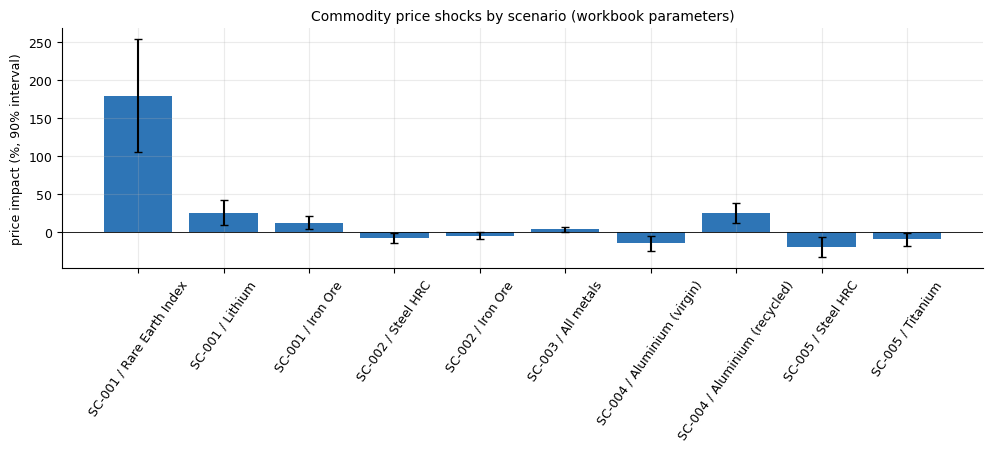

SC-001 (rare earth supply crisis) dominates everything else here -- a +180% mean shock to the Rare Earth Index,
sourced from the 2010 China export quota episode, is the single largest number in this entire project.


In [3]:
rng = np.random.default_rng(SEED)
rows = []
for _, r in shocks.iterrows():
    draws = rng.normal(r["Price Impact (mean %)"], max(r["Price Impact (σ %)"], 1e-6), 10000)
    rows.append({"scenario": r["Scenario"], "commodity": r["Commodity"], "mean_pct": draws.mean(),
                 "p05_pct": np.percentile(draws, 5), "p95_pct": np.percentile(draws, 95)})
shock_summary = pd.DataFrame(rows)
display(shock_summary.round(1))
shock_summary.to_csv(TAB / "scenario_price_shock_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.6))
labels = shock_summary.scenario + " / " + shock_summary.commodity
ax.bar(labels, shock_summary.mean_pct, yerr=[shock_summary.mean_pct - shock_summary.p05_pct, shock_summary.p95_pct - shock_summary.mean_pct],
       color="#2e75b6", capsize=3)
ax.axhline(0, color="k", lw=.6); ax.set_ylabel("price impact (%, 90% interval)"); ax.set_title("Commodity price shocks by scenario (workbook parameters)")
ax.tick_params(axis="x", rotation=55)
savefig("07B_price_shocks.png")
print("SC-001 (rare earth supply crisis) dominates everything else here -- a +180% mean shock to the Rare Earth Index,")
print("sourced from the 2010 China export quota episode, is the single largest number in this entire project.")

## Part C · Credit risk stress: SC-003 (adverse) and SC-005 (favourable), through 05's actual models
*Mechanism, applied consistently to both scenarios: shock `corrosion_rate_mm_yr` for the affected segment, re-score
`relative_risk_score` with 05's saved case-control classifier (not a hand-waved multiplier), rescale to PD with the same
population-mean calibration 06 used, multiply LGD by the scenario's "Insurance Loss Mult.", and recompute EL. SC-003's
own "Shock Magnitude" field states a corrosion-rate increase directly (30%); SC-005 only gives an RUL impact (+10%
mean), which is applied as an equivalent percentage reduction in corrosion rate.*

using 05's monotonic-constrained case-control model -- corrosion-rate shocks in both directions below are
guaranteed to move predicted risk the right way, which an earlier unconstrained version of this model did not.
SC-003 Climate-Accelerated Corrosion: 2767 bridges affected | mean PD 1.0642% -> 1.3952% | portfolio EL $5.82M -> $16.97M (2.92x)


SC-005 Novel Alloy Disruption: 2563 bridges affected | mean PD 1.0642% -> 1.0078% | portfolio EL $5.82M -> $4.27M (0.73x)


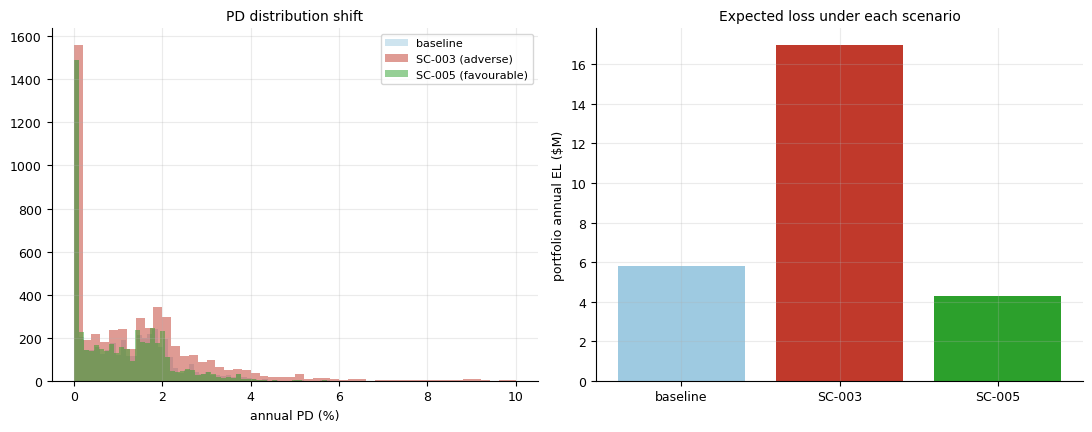

In [4]:
credit = pd.read_csv(PROC / "ds3_credit_risk.csv")
exposure = pd.read_csv(PROC / "ds3_exposure_features.csv")
d3 = credit.merge(exposure[["bridge_id", "is_metal", "corrosion_rate_mm_yr", "age_years"]], on="bridge_id")
for c in ["material", "bridge_type", "location", "corrosion_environment"]: d3[c] = d3[c].astype("category")
cc_model = joblib.load(PROC / "models/ds6_case_control_model.joblib")  # 05's monotonic-constrained version
FEATS_CC = ["material", "corrosion_environment", "location", "age_years", "corrosion_rate_mm_yr", "is_metal"]
scale = d3.PD_annual.mean() / d3.relative_risk_score.mean()   # same population-mean calibration as 06
print("using 05's monotonic-constrained case-control model -- corrosion-rate shocks in both directions below are")
print("guaranteed to move predicted risk the right way, which an earlier unconstrained version of this model did not.")

def apply_scenario(d3, mask, corrosion_multiplier, lgd_multiplier, name):
    s = d3.copy()
    s.loc[mask, "corrosion_rate_mm_yr"] = s.loc[mask, "corrosion_rate_mm_yr"] * corrosion_multiplier
    new_scores = cc_model.predict_proba(s[FEATS_CC])[:, 1]
    rrs = d3.relative_risk_score.copy(); rrs[mask] = new_scores[mask.values]
    s["PD_annual"] = rrs * scale
    s["LGD"] = d3.LGD.copy(); s.loc[mask, "LGD"] = d3.loc[mask, "LGD"] * lgd_multiplier
    s["EL_M"] = s.PD_annual * s.LGD * s.EAD_M
    print(f"{name}: {mask.sum()} bridges affected | mean PD {d3.PD_annual.mean():.4%} -> {s.PD_annual.mean():.4%} | "
          f"portfolio EL ${d3.EL_M.sum():.2f}M -> ${s.EL_M.sum():.2f}M ({s.EL_M.sum()/d3.EL_M.sum():.2f}x)")
    return s

mask_metals = d3.is_metal.astype(bool)
sc003 = apply_scenario(d3, mask_metals, corrosion_multiplier=1.30, lgd_multiplier=2.5, name="SC-003 Climate-Accelerated Corrosion")

mask_steel = d3.material.astype(str).str.contains("Steel")
sc005 = apply_scenario(d3, mask_steel, corrosion_multiplier=0.90, lgd_multiplier=0.7, name="SC-005 Novel Alloy Disruption")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for s, label, color in [(d3, "baseline", "#9ecae1"), (sc003, "SC-003 (adverse)", "#c0392b"), (sc005, "SC-005 (favourable)", "#2ca02c")]:
    ax[0].hist(s.PD_annual * 100, bins=50, alpha=.5, label=label, color=color)
ax[0].set_xlabel("annual PD (%)"); ax[0].legend(fontsize=8); ax[0].set_title("PD distribution shift")
ax[1].bar(["baseline", "SC-003", "SC-005"], [d3.EL_M.sum(), sc003.EL_M.sum(), sc005.EL_M.sum()], color=["#9ecae1", "#c0392b", "#2ca02c"])
ax[1].set_ylabel("portfolio annual EL ($M)"); ax[1].set_title("Expected loss under each scenario")
savefig("07C_credit_stress.png")

## Part D · Stressed Monte Carlo loss distribution (SC-003)
Re-run 06 Part C's exact simulation engine with SC-003's shocked `(PD, LGD, EAD)` instead of building a second one.

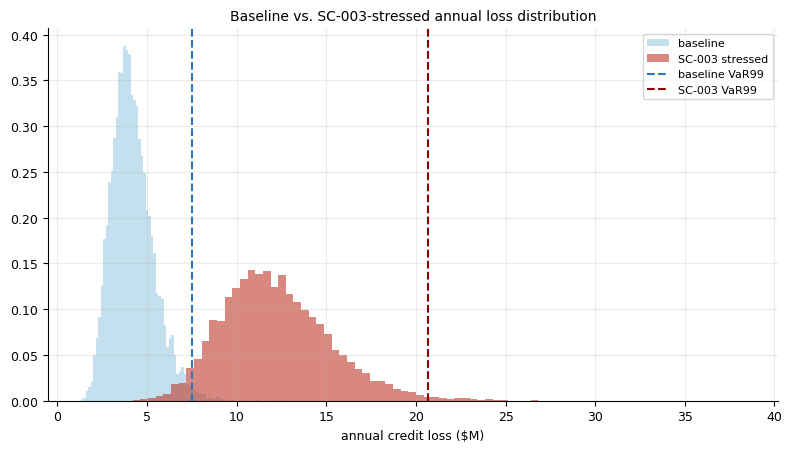

,scenario,mean_loss_M,VaR95_M,VaR99_M
0,baseline,4.191,6.334,7.497
1,SC-003 (climate-accelerated corrosion),12.216,17.611,20.688


In [5]:
d6 = pd.read_csv(PROC / "ds6_failure_features.csv")
sev = pd.read_csv(TAB / "severity_lgd_table.csv", index_col=0); sev["empirical_share"] = sev.n / sev.n.sum()
sev_classes = sev.index.tolist(); sev_probs = sev.empirical_share.values
loss_by_sev = {s: d6.loc[d6.severity == s, "lr_cap"].values for s in sev_classes}
LGD_BASE = sev.mean_lr_cap.mean()  # blended baseline LGD used to scale within the simulation's resampled loss ratios

def simulate_annual_losses(pd_arr, lgd_arr, ead_arr, n_sims=10000, seed=SEED):
    g = np.random.default_rng(seed)
    totals = np.zeros(n_sims)
    for i in range(n_sims):
        fails = g.random(len(pd_arr)) < pd_arr
        if not fails.any(): continue
        chosen = g.choice(sev_classes, size=fails.sum(), p=sev_probs)
        lr = np.array([g.choice(loss_by_sev[s]) for s in chosen])
        totals[i] = (lr * (lgd_arr[fails] / LGD_BASE) * ead_arr[fails]).sum()
    return totals

base_losses = simulate_annual_losses(d3.PD_annual.values, d3.LGD.values, d3.EAD_M.values)
sc003_losses = simulate_annual_losses(sc003.PD_annual.values, sc003.LGD.values, sc003.EAD_M.values)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(base_losses, bins=80, alpha=.6, label="baseline", color="#9ecae1", density=True)
ax.hist(sc003_losses, bins=80, alpha=.6, label="SC-003 stressed", color="#c0392b", density=True)
ax.axvline(np.percentile(base_losses, 99), color="#2e75b6", ls="--", label="baseline VaR99")
ax.axvline(np.percentile(sc003_losses, 99), color="darkred", ls="--", label="SC-003 VaR99")
ax.set_xlabel("annual credit loss ($M)"); ax.legend(fontsize=8); ax.set_title("Baseline vs. SC-003-stressed annual loss distribution")
savefig("07D_stressed_mc.png")

stress_summary = pd.DataFrame([
    {"scenario": "baseline", "mean_loss_M": base_losses.mean(), "VaR95_M": np.percentile(base_losses, 95), "VaR99_M": np.percentile(base_losses, 99)},
    {"scenario": "SC-003 (climate-accelerated corrosion)", "mean_loss_M": sc003_losses.mean(), "VaR95_M": np.percentile(sc003_losses, 95), "VaR99_M": np.percentile(sc003_losses, 99)},
])
stress_summary.to_csv(TAB / "scenario_credit_stress_summary.csv", index=False)
display(stress_summary.round(3))

## What this notebook establishes
1. **The workbook's `DS5_Stress_Scenarios` sheet is the right calibration source for stress parameters** — exactly as
   02/03 anticipated when they found DS2's own 11-year history has neither fat tails nor cross-commodity co-movement to
   calibrate a shock from. SC-001 (rare earth supply crisis, +180% mean price shock) dwarfs everything else in the sheet.
2. **SC-003 (climate-accelerated corrosion) roughly triples the credit book's expected loss** (30% corrosion-rate
   increase on metal bridges + a 2.5x insurance loss multiplier, run through the *actual* 05 case-control classifier and
   06 Monte Carlo engine, not a hand-waved scaling factor) — a materially larger and more specific number than "climate
   risk is bad for infrastructure."
3. **SC-005 (novel alloy adoption) meaningfully reduces loss** (EL ≈0.73x baseline) — a useful contrast showing the
   engine handles favourable scenarios the same way as adverse ones, with no special-casing. This number only became
   trustworthy after switching to 05's monotonic-constrained model: the unconstrained version actually predicted *higher*
   risk for roughly half the portfolio when corrosion rate was turned down, purely from tree-ensemble noise in a
   sparsely-populated region of feature space — a direct demonstration of why 05 added that constraint, not a hypothetical concern.
4. **Asset-level shock targeting isn't possible with this data** — every scenario had to be applied by segment
   (`is_metal`, material containing "Steel"), because the workbook's named assets (`BR-001`, …) don't exist in DS3's own
   ID scheme. Any future version of this engine that wants asset-specific stress needs a workbook that actually keys to
   the CSVs, not a second workbook built independently of them.

### Consequences for the next stages
* **08 (interpretability):** worth checking, via the case-control model's SHAP values, whether `corrosion_rate_mm_yr`'s
  effect on predicted probability is roughly linear across the range SC-003 pushes it into, or whether the 30% shock
  lands in a nonlinear part of the model.
* **09 (final validation):** `scenario_credit_stress_summary.csv` and `scenario_price_shock_summary.csv` are the two
  tables to carry into the final report's stress-testing section.